In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

In [ ]:
df = pd.read_csv('Titanic-Dataset.csv')
print(df.shape)
print(f'Количество дубликатов: {df.duplicated().sum()}')
df

(891, 12)
Количество дубликатов: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


В датасете 891 запись и 12 столбцов. Дубликатов строк не обнаружено. Целевая переменная `Survived` принимает значения 0 и 1: 549 пассажиров (61,6%) не выжили, 342 (38,4%) выжили. Классы представлены неравномерно, поэтому одной Accuracy для оценки недостаточно.

В таблице есть числовые и категориальные признаки. `PassengerId` является идентификатором, а `Name` и `Ticket` содержат большое количество уникальных значений. Их прямое использование может привести к запоминанию отдельных пассажиров, поэтому далее из `Name` извлекается только обращение (`Title`), а `PassengerId` и `Ticket` в модель не передаются.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Больше всего пропусков в `Cabin` — 687 (около 77,1%), далее `Age` — 177 (19,9%) и `Embarked` — 2. Остальные столбцы заполнены полностью.


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Survived'])
y = df['Survived']

def add_features(X_train, X_test):
    X_train, X_test = X_train.copy(), X_test.copy()

    for dataset in (X_train, X_test):
        dataset['Title'] = dataset['Name'].str.extract(r'([A-Za-z]+)\.')
        dataset['Title'] = dataset['Title'].replace(['Mlle', 'Ms'], 'Miss').replace('Mme', 'Mrs')
        dataset.loc[~dataset['Title'].isin(['Miss', 'Mr', 'Mrs', 'Master']), 'Title'] = 'Rare'
        dataset['deck'] = dataset['Cabin'].str[0].fillna('U')

    age_medians = X_train.groupby(['Title', 'Pclass'])['Age'].median()

    for dataset in (X_train, X_test):
        medians_series = dataset.set_index(['Title', 'Pclass']).index.map(age_medians)
        dataset['Age'] = dataset['Age'].fillna(pd.Series(medians_series, index=dataset.index))

    return X_train, X_test

`Age` полезен для предсказания, поэтому пропуски заполняются медианой внутри групп по `Title` и `Pclass`. Для неизвестной палубы создаётся отдельная категория `U`, а пропуски в `Embarked` обрабатываются наиболее частым значением. Такой подход сохраняет информацию о наличии/отсутствии данных о каюте и не удаляет значительную часть пассажиров.

Из имени извлекается `Title`: редкие обращения объединяются в категорию `Rare`, а варианты `Mlle`, `Ms` и `Mme` приводятся к соответствующим категориям. Из `Cabin` извлекается первая буква — палуба (`deck`), а при отсутствии каюты записывается `U`. Медианы возраста вычисляются только по обучающей выборке в группах `Title` и `Pclass`, после чего применяются к обеим выборкам. Таким образом, статистика тестовой выборки не используется при обучении преобразования.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_test = add_features(X_train, X_test)
train = X_train.assign(Survived=y_train)

Данные разделены на обучающую и тестовую выборки в соотношении 80/20. Параметр `stratify=y` сохраняет соотношение классов, а `random_state=42` обеспечивает воспроизводимость. Получено 712 объектов для обучения и 179 для итогового тестирования. Все модели используют одно и то же разбиение.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

num = ['Age', 'Fare', 'SibSp', 'Parch']
cat = ['Pclass', 'Sex', 'Embarked', 'Title', 'deck']


preprocess = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median'))
    ]), num),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat)
])

preprocess_scaled = ColumnTransformer([
    ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
    ]),num,),
    ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat)
 ])


preprocess.set_output(transform="pandas")
X_ready = preprocess.fit_transform(X_train)
train = X_ready.assign(Survived=y_train)
train.head()

,num__Age,num__Fare,num__SibSp,num__Parch,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,cat__Sex_female,cat__Sex_male,cat__Embarked_C,...,cat__deck_A,cat__deck_B,cat__deck_C,cat__deck_D,cat__deck_E,cat__deck_F,cat__deck_G,cat__deck_T,cat__deck_U,Survived
692,27.0,56.4958,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
481,30.0,0.0000,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
527,40.0,221.7792,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0
855,18.0,9.3500,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
801,31.0,26.2500,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1


Числовые признаки (`Age`, `Fare`, `SibSp`, `Parch`) обрабатываются медианой, категориальные (`Pclass`, `Sex`, `Embarked`, `Title`, `deck`) — наиболее частым значением, после чего преобразуются методом One-Hot Encoding. Для категорий, которые могут встретиться только в тестовой части, задано `handle_unknown='ignore'`.

Масштабирование нужно прежде всего для SVM и KNN: эти алгоритмы используют расстояния или геометрию пространства признаков, поэтому признаки с большим числовым диапазоном могут непропорционально влиять на результат. Для дерева решений, случайного леса и градиентного бустинга масштабирование обычно не требуется: их разбиения основаны на порогах отдельных признаков. Поэтому в коде для SVM и KNN используется `preprocess_scaled`, а для деревьев — `preprocess`. Предобработка внутри Pipeline обучается на обучающей выборке.

In [ ]:
stats = train.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skew'] = train.skew()
stats['kurtosis'] = train.kurtosis()
stats

,mean,std,min,50%,max,skew,kurtosis
num__Age,29.398062,13.460508,0.42,27.0000,80.0000,0.414067,0.597859
num__Fare,31.819826,48.059104,0.00,14.4542,512.3292,4.646190,32.518880
num__SibSp,0.492978,1.060720,0.00,0.0000,8.0000,3.815617,19.317828
num__Parch,0.390449,0.838134,0.00,0.0000,6.0000,2.842562,10.190391
cat__Pclass_1,0.240169,0.427486,0.00,0.0000,1.0000,1.219050,-0.515373
cat__Pclass_2,0.210674,0.408074,0.00,0.0000,1.0000,1.422001,0.022141
cat__Pclass_3,0.549157,0.497927,0.00,1.0000,1.0000,-0.198004,-1.966326
cat__Sex_female,0.355337,0.478952,0.00,0.0000,1.0000,0.605783,-1.637635
cat__Sex_male,0.644663,0.478952,0.00,1.0000,1.0000,-0.605783,-1.637635
cat__Embarked_C,0.195225,0.396652,0.00,0.0000,1.0000,1.541067,0.375935


In [ ]:
y_train.value_counts(sort=False)

,count
Survived,
1,273
0,439


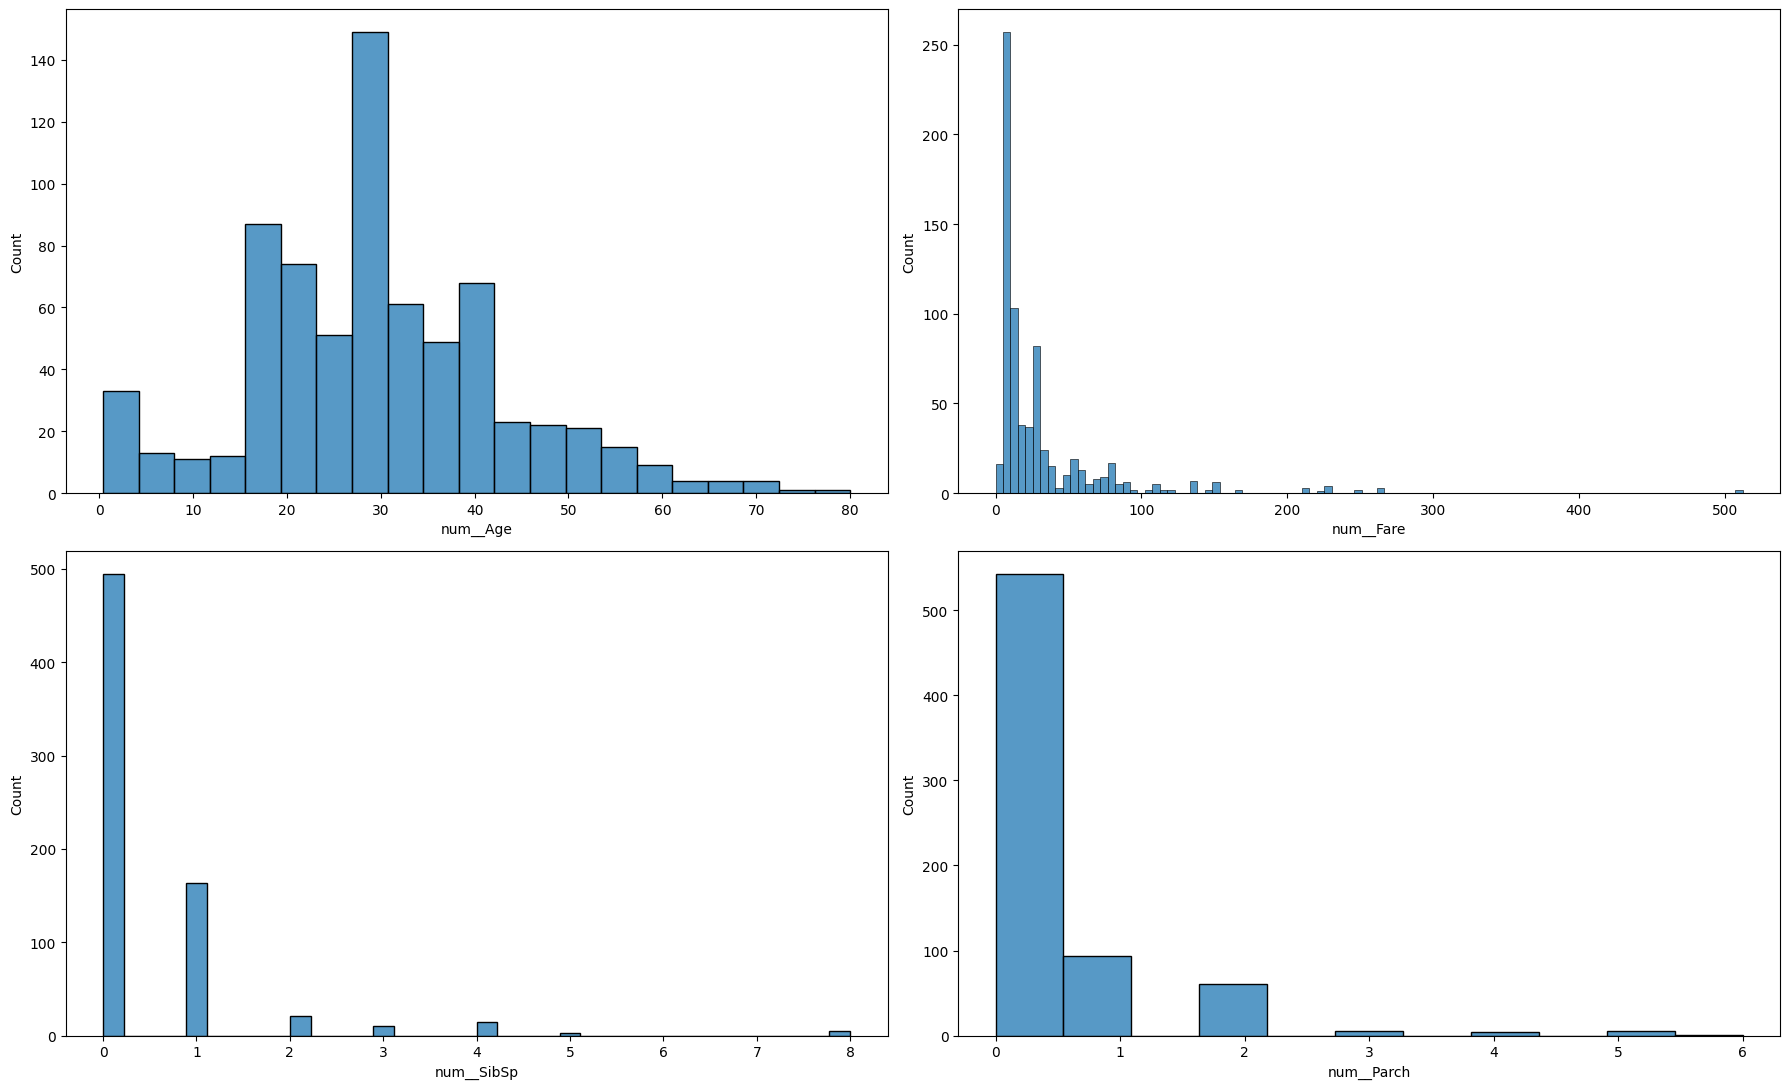

In [ ]:
feat_cols = train.filter(like='num').columns

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, c in zip(axes.ravel(), feat_cols):
    sns.histplot(train[c], ax=ax)

plt.tight_layout()
plt.show()

По гистограммам видно, что большинство пассажиров — люди молодого и среднего возраста. Распределение `Fare` имеет длинный правый хвост: большинство значений сравнительно небольшие, но есть отдельные очень высокие тарифы. Признаки `SibSp` и `Parch` чаще всего равны нулю, то есть у большинства пассажиров в данных нет указанных родственников на борту.

Это подтверждается коэффициентами асимметрии: для `Fare` он составляет около 4,65, для `SibSp` — 3,82, для `Parch` — 2,84. Следовательно, эти распределения заметно скошены вправо и содержат редкие большие значения.

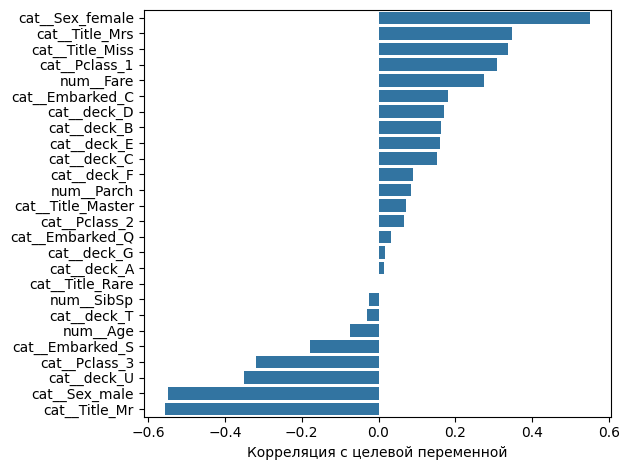

In [ ]:
correlations = X_ready.corrwith(y_train).sort_values(ascending=False)
plot = sns.barplot(y=correlations.index, x=correlations)

plot.set(xlabel="Корреляция с целевой переменной", ylabel="")

plt.tight_layout()
plt.show()

<Axes: >

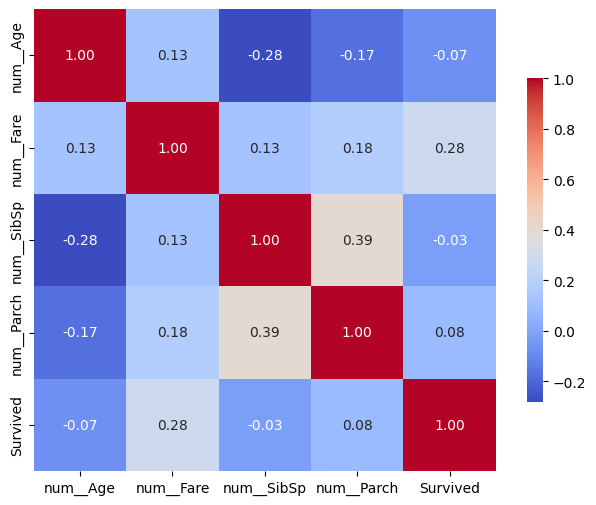

In [ ]:
corr_matrix = train[feat_cols.tolist() + ['Survived']].corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={'shrink': 0.7})

На графике корреляций заметна положительная связь выживания с категориями `Sex_female`, `Title_Mrs`, `Title_Miss` и `Pclass_1`. Отрицательная связь наблюдается у `Sex_male`, `Title_Mr` и `Pclass_3`. Это согласуется с историческими особенностями эвакуации пассажиров «Титаника» и указывает, что пол, обращение и класс билета содержат полезную для классификации информацию.

Корреляция показывает статистическую связь, но сама по себе не доказывает причинность. Кроме того, некоторые признаки взаимосвязаны: например, `Sex` и `Title` частично дублируют информацию друг о друге.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

baseline = DummyClassifier(strategy='most_frequent')
tree = Pipeline([
    ('prep', preprocess),
    ('model', DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ))
])
rf = Pipeline([
    ('prep', preprocess),
    ('model', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])
gb = Pipeline([
    ('prep', preprocess),
    ('model',GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])
svm = Pipeline([
    ('prep', preprocess_scaled),
    ('model', SVC(
        C=1.0,
        kernel='rbf',
        gamma='scale',
        probability=True
    ))
])
knn = Pipeline([
    ('prep', preprocess_scaled),
    ('model', KNeighborsClassifier(
        n_neighbors=7,
        weights='distance'
    ))
])

- **Dummy baseline** всегда выбирает наиболее частый класс и служит простой точкой отсчёта.
- **Decision Tree** строит последовательность условий по признакам.
- **Random Forest** объединяет предсказания множества деревьев, обученных на разных подвыборках.
- **Gradient Boosting** строит деревья последовательно, стараясь исправлять ошибки предыдущих.
- **SVM** ищет разделяющую границу между классами; в этой работе используется RBF-ядро.
- **KNN** относит объект к классу его ближайших соседей; здесь рассматриваются 7 соседей.

Для всех моделей ниже рассчитываются одинаковые метрики на одной тестовой выборке.

In [ ]:
def evaluate(name, model, X_test, y_test, X_train, y_train):
  pred_train = model.predict(X_train)
  pred = model.predict(X_test)
  proba = model.predict_proba(X_test)[:, 1]
  return {
      'model': name,
      'accuracy_test': accuracy_score(y_test, pred),
      'accuracy_train':accuracy_score(y_train, pred_train),
      'precision': precision_score(y_test, pred, zero_division=0),
      'recall': recall_score(y_test, pred, zero_division=0),
      'f1_test': f1_score(y_test, pred, zero_division=0),
      'f1_train': f1_score(y_train, pred_train, zero_division=0),
      'roc_auc': roc_auc_score(y_test, proba)
  }

models = {
    'baseline': baseline,
    'Decision Tree': tree,
    'Random Forest': rf,
    'Gradient Boosting': gb,
    'SVM': svm,
    'KNN': knn
}

results = []
coefs = []
for name, model in models.items():
  model.fit(X_train, y_train)
  results.append(evaluate(name, model, X_test, y_test, X_train, y_train))

results = (pd.DataFrame(results).sort_values('f1_test', ascending=False))
results



,model,accuracy_test,accuracy_train,precision,recall,f1_test,f1_train,roc_auc
4,SVM,0.837989,0.855337,0.833333,0.724638,0.775194,0.798434,0.854150
5,KNN,0.798883,0.985955,0.753846,0.710145,0.731343,0.981413,0.829644
3,Gradient Boosting,0.804469,0.862360,0.793103,0.666667,0.724409,0.808594,0.844862
2,Random Forest,0.804469,0.904494,0.803571,0.652174,0.720000,0.866667,0.848287
1,Decision Tree,0.798883,0.849719,0.811321,0.623188,0.704918,0.780287,0.829447
0,baseline,0.614525,0.616573,0.000000,0.000000,0.000000,0.000000,0.500000


Accuracy показывает долю правильных ответов среди всех объектов; Precision — долю действительно выживших среди предсказанных моделью выжившими; Recall — долю найденных моделью выживших среди всех реально выживших. F1-score объединяет Precision и Recall в одно значение и является основной метрикой этой лабораторной.

Лучший результат показала SVM: Accuracy = 0,838, Precision = 0,833, Recall = 0,725, F1 = 0,775. Далее идут KNN (F1 = 0,731), Gradient Boosting (0,724), Random Forest (0,720) и Decision Tree (0,705). Все пять обученных моделей преодолели требуемый порог F1 > 0,70; дерево решений прошло его с небольшим запасом. У baseline Accuracy равна 0,615, но F1 равен нулю: модель всегда предсказывает класс 0 и не находит ни одного выжившего.

Сравнение обучающих и тестовых результатов показывает наиболее заметное переобучение у KNN: обучающий F1 около 0,981, тестовый — 0,731. У Random Forest разрыв тоже заметен (0,867 против 0,720). У SVM значения ближе друг к другу (0,798 и 0,775), поэтому её результат выглядит наиболее устойчивым на новых данных.

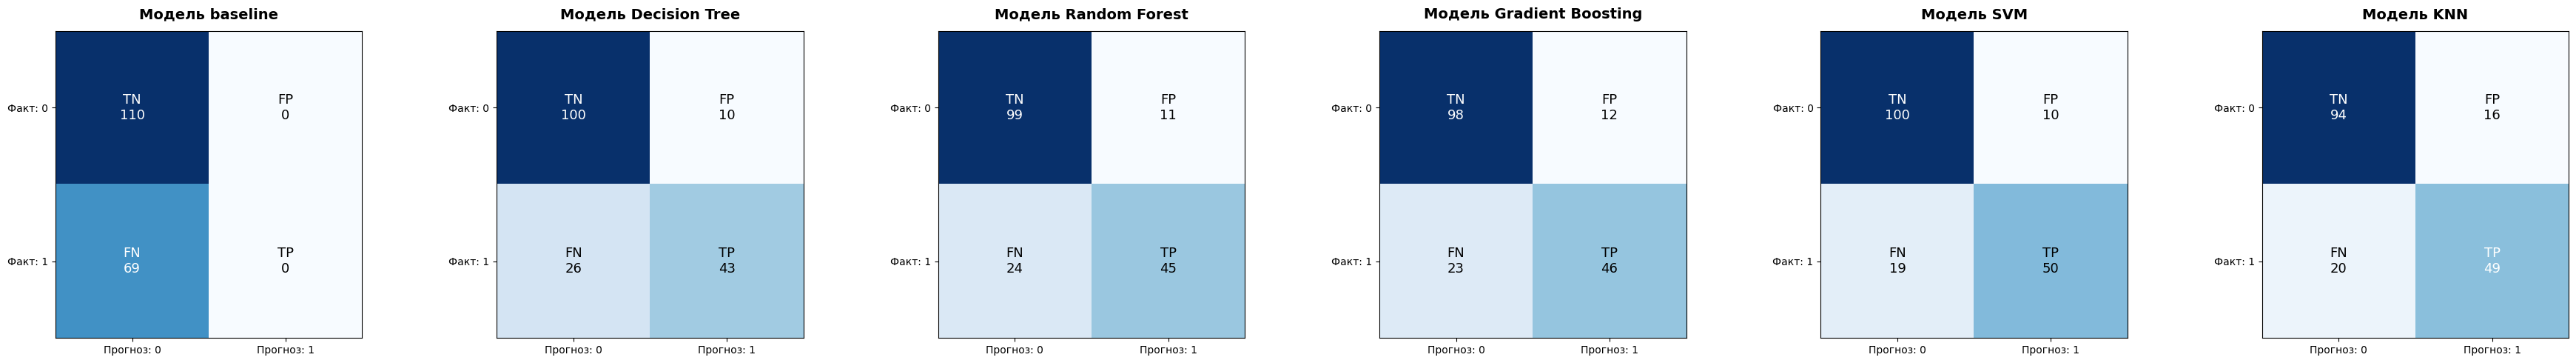

In [ ]:
from sklearn.metrics import confusion_matrix

def draw_conf_matrix(y_test, pred, title, ax=None):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    im = ax.imshow(cm, cmap='Blues')
    for (r, col), value in np.ndenumerate(cm):
        name = {(0, 0): 'TN', (0, 1): 'FP', (1, 0): 'FN', (1, 1): 'TP'}[(r, col)]
        ax.text(col, r, f'{name}\n{value}', ha='center', va='center', fontsize=13,
                color='white' if value > cm.max() / 2 else 'black')

    ax.set_title(title, fontsize=14, fontweight='bold', pad=12)
    ax.set_xticks([0, 1], ['Прогноз: 0', 'Прогноз: 1'])
    ax.set_yticks([0, 1], ['Факт: 0', 'Факт: 1'])

n_models = len(models)
fig, axes = plt.subplots(ncols=n_models, figsize=(6 * n_models, 5))
axes = np.atleast_1d(axes)

for ax, (name, model) in zip(axes, models.items()):
    pred = model.predict(X_test)
    draw_conf_matrix(y_test, pred, f'Модель {name}', ax=ax)

plt.tight_layout()
plt.show()




В контексте задачи:

- **False Positive (FP)** — модель предсказала, что пассажир выжил, хотя фактически он не выжил.
- **False Negative (FN)** — модель предсказала, что пассажир не выжил, хотя фактически он выжил.

Для наглядности значения матриц (TN, FP, FN, TP) сведены в таблицу. TN — верно предсказанные случаи класса 0, TP — верно предсказанные случаи класса 1.

| Модель | TN | FP | FN | TP |
|---|---:|---:|---:|---:|
| Baseline | 110 | 0 | 69 | 0 |
| Decision Tree | 100 | 10 | 26 | 43 |
| Random Forest | 99 | 11 | 24 | 45 |
| Gradient Boosting | 98 | 12 | 23 | 46 |
| SVM | 100 | 10 | 19 | 50 |
| KNN | 94 | 16 | 20 | 49 |

У лучшей модели SVM больше ложных отрицательных ответов (19), чем ложных положительных (10). То есть модель чаще ошибочно относит выжившего пассажира к погибшим, чем наоборот.

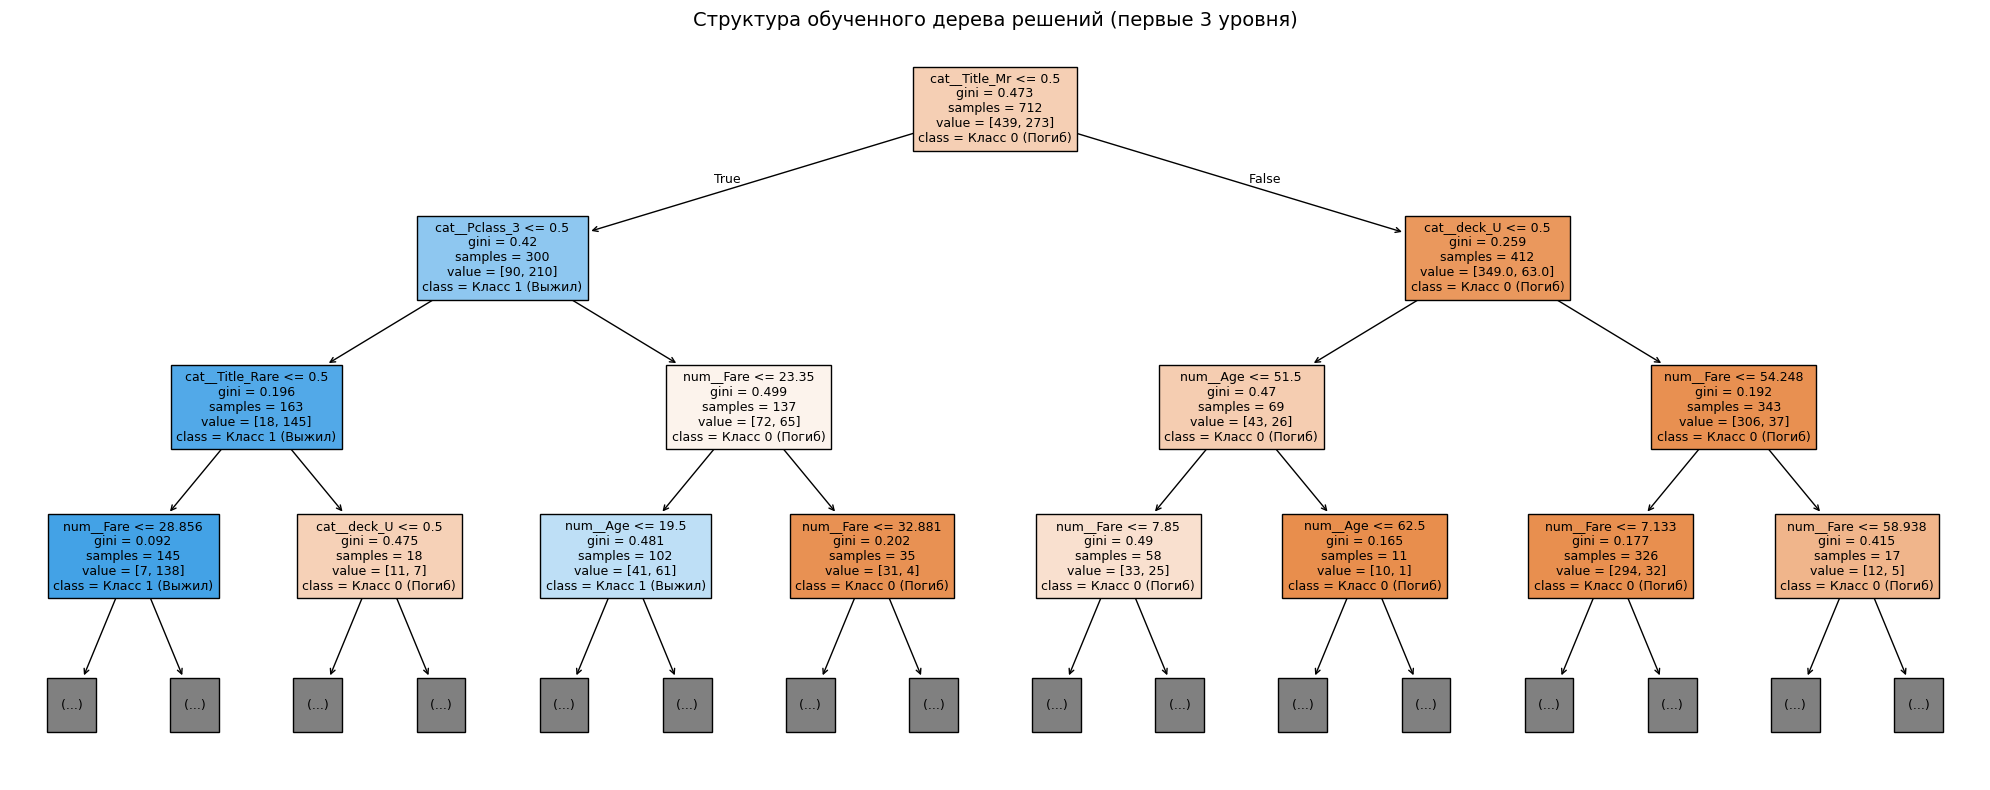

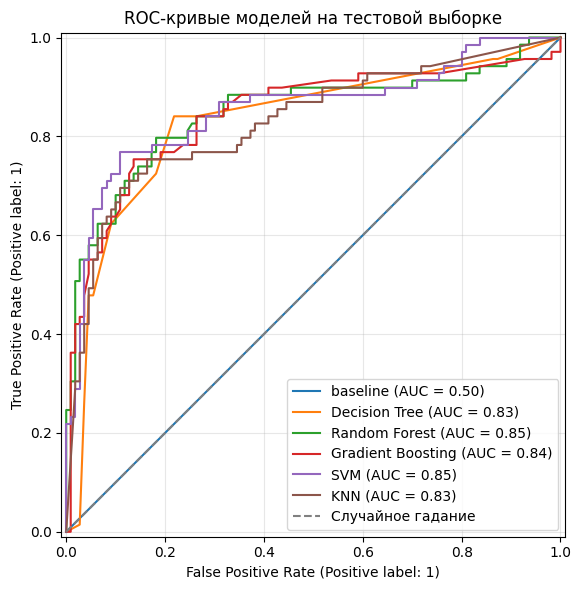

In [90]:
from sklearn.tree import plot_tree
from sklearn.metrics import RocCurveDisplay


plt.figure(figsize=(20, 8))
dt_estimator = tree.named_steps['model']
feature_names = tree.named_steps['prep'].get_feature_names_out()
plot_tree(dt_estimator, filled=True, feature_names=feature_names,
          class_names=['Класс 0 (Погиб)', 'Класс 1 (Выжил)'], fontsize=9, max_depth=3)
plt.title('Структура обученного дерева решений (первые 3 уровня)', fontsize=14)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Случайное гадание')
ax.set_title('ROC-кривые моделей на тестовой выборке')
ax.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

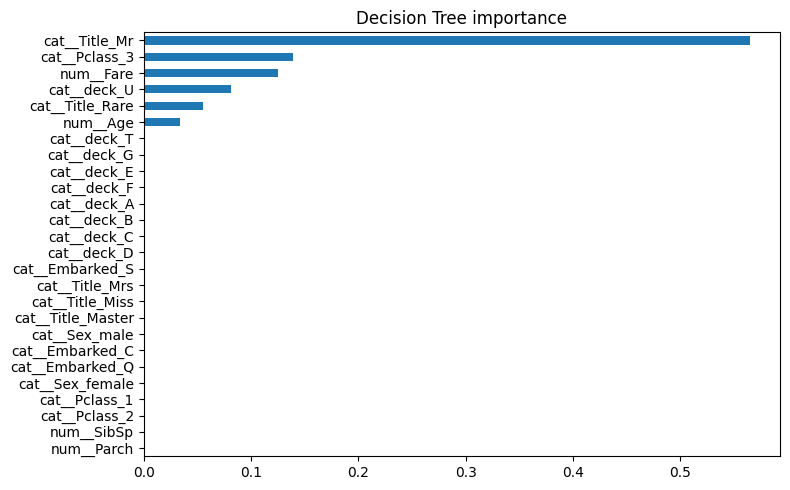

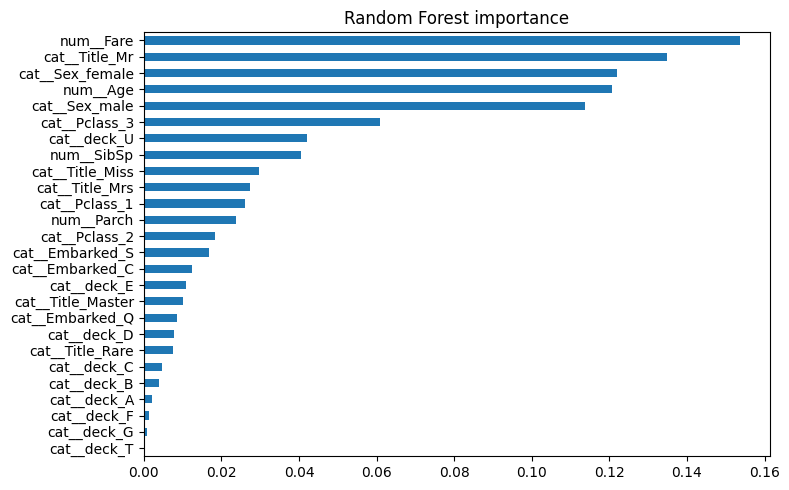

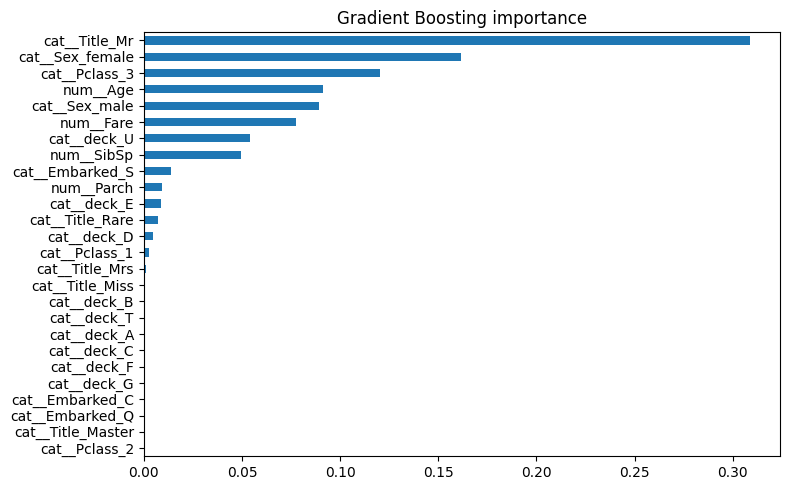

In [ ]:
def plot_importance(model, title):
    est = model.steps[-1][1] if hasattr(model, 'steps') else model
    names = list(model[:-1].get_feature_names_out())
    imp = pd.Series(est.feature_importances_, index=names).sort_values()
    imp.plot(kind='barh', figsize=(8, 5))
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_importance(tree, 'Decision Tree importance')
plot_importance(rf,   'Random Forest importance')
plot_importance(gb,   'Gradient Boosting importance')

На графиках видны различия между моделями:

- **Decision Tree:** сильнее всего выделяется `Title_Mr` (примерно 0,56); далее идут `Pclass_3`, `Fare` и категория неизвестной палубы `deck_U`.
- **Random Forest:** важность распределена равномернее. Наиболее заметны `Fare`, `Title_Mr`, `Sex_female`, `Age` и `Sex_male`.
- **Gradient Boosting:** на первом месте снова `Title_Mr` (примерно 0,31), затем `Sex_female`, `Pclass_3`, `Age` и `Sex_male`.

В целом результаты согласуются с корреляционным анализом: пол/обращение и класс билета оказываются значимыми для всех трёх моделей; также заметны тариф и возраст. При этом важность зависит от конкретного алгоритма и распределения взаимосвязанных признаков. Она показывает, насколько признак помогал модели при построении разбиений, но не доказывает, что этот признак является причиной выживания. На результат могли влиять и другие, неучтённые обстоятельства.

In [ ]:
best_model = models['SVM']
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

error_df = df.loc[X_test.index].copy()
error_df['Title'] = X_test['Title']
error_df['deck'] = X_test['deck']
error_df['Actual'] = y_test
error_df['Predicted'] = y_pred
error_df['Proba_Survived'] = y_proba.round(3)

error_df['Error_Type'] = 'Correct'
error_df.loc[(error_df['Actual'] == 0) & (error_df['Predicted'] == 1), 'Error_Type'] = 'FP (Ложное выживание)'
error_df.loc[(error_df['Actual'] == 1) & (error_df['Predicted'] == 0), 'Error_Type'] = 'FN (Ложная гибель)'

group_errors = error_df.groupby(['Sex', 'Pclass']).apply(
    lambda g: pd.Series({
        'Всего': len(g),
        'Ошибок': (g['Actual'] != g['Predicted']).sum(),
        'Доля ошибок (%)': round((g['Actual'] != g['Predicted']).mean() * 100, 1),
        'FP': (g['Error_Type'] == 'FP (Ложное выживание)').sum(),
        'FN': (g['Error_Type'] == 'FN (Ложная гибель)').sum()
    })
)
group_errors

/tmp/ipykernel_740/2632135219.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  group_errors = error_df.groupby(['Sex', 'Pclass']).apply(


Всего  Ошибок  Доля ошибок (%)   FP   FN
Sex    Pclass                                          
female 1        15.0     1.0              6.7  1.0  0.0
       2        18.0     1.0              5.6  1.0  0.0
       3        28.0     8.0             28.6  6.0  2.0
male   1        30.0    11.0             36.7  2.0  9.0
       2        16.0     2.0             12.5  0.0  2.0
       3        72.0     6.0              8.3  0.0  6.0

Для SVM наибольшая доля ошибок наблюдается среди мужчин первого класса — 11 ошибок из 30 объектов (36,7%). Среди женщин третьего класса ошибочно классифицированы 8 из 28 пассажиров (28,6%). Для остальных групп доля ошибок ниже: женщины первого и второго классов — 6,7% и 5,6%, мужчины второго и третьего классов — 12,5% и 8,3% соответственно.

Это результаты только тестовой выборки, поэтому небольшие группы не позволяют делать универсальные выводы о всех пассажирах. Однако они показывают, что модель ошибается неравномерно для разных сочетаний пола и класса.

In [ ]:
mistakes = error_df[error_df['Error_Type'] != 'Correct']
display(mistakes.sort_values(by='Proba_Survived', ascending=False).head(5))
display(mistakes.sort_values(by='Proba_Survived', ascending=True).head(5))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,deck,Actual,Predicted,Proba_Survived,Error_Type
199,200,0,2,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24.0,0,0,248747,13.0000,NaN,S,Miss,U,0,1,0.891,FP (Ложное выживание)
297,298,0,1,"Allison, Miss. Helen Loraine",female,2.0,1,2,113781,151.5500,C22 C26,S,Miss,C,0,1,0.887,FP (Ложное выживание)
502,503,0,3,"O'Sullivan, Miss. Bridget Mary",female,NaN,0,0,330909,7.6292,NaN,Q,Miss,U,0,1,0.880,FP (Ложное выживание)
501,502,0,3,"Canavan, Miss. Mary",female,21.0,0,0,364846,7.7500,NaN,Q,Miss,U,0,1,0.850,FP (Ложное выживание)
578,579,0,3,"Caram, Mrs. Joseph (Maria Elias)",female,NaN,1,0,2689,14.4583,NaN,C,Mrs,U,0,1,0.773,FP (Ложное выживание)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,deck,Actual,Predicted,Proba_Survived,Error_Type
570,571,1,2,"Harris, Mr. George",male,62.0,0,0,S.W./PP 752,10.5000,NaN,S,Mr,U,1,0,0.123,FN (Ложная гибель)
271,272,1,3,"Tornquist, Mr. William Henry",male,25.0,0,0,LINE,0.0000,NaN,S,Mr,U,1,0,0.126,FN (Ложная гибель)
455,456,1,3,"Jalsevac, Mr. Ivan",male,29.0,0,0,349240,7.8958,NaN,C,Mr,U,1,0,0.127,FN (Ложная гибель)
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S,Mr,U,1,0,0.127,FN (Ложная гибель)
146,147,1,3,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,0,0,350043,7.7958,NaN,S,Mr,U,1,0,0.128,FN (Ложная гибель)


Среди ложноположительных предсказаний в выведенных примерах преобладают женщины: модель часто связывает женский пол и соответствующий `Title` с большей вероятностью выживания, хотя конкретные пассажирки не выжили. Среди ложноотрицательных примеров — мужчины, которые фактически выжили, но были отнесены моделью к классу 0. Эти случаи показывают, что общая закономерность не описывает судьбу каждого отдельного пассажира.

Прямые идентификаторы `PassengerId` и `Ticket` не входят в список признаков модели. Из `Name` используется только категория `Title`, а из `Cabin` — первая буква палубы (`deck`), то есть сами значения имени, билета и номера каюты модель не получает. Поэтому прямое запоминание конкретных пассажиров по идентификаторам маловероятно. При этом `deck_U` может выступать косвенным сигналом: отсутствие сведений о каюте связано не случайным образом с другими характеристиками пассажира.